<a href="https://colab.research.google.com/github/M-Hadi-Hidayat/Tugas-Machine-Learning/blob/main/Tugas_3_Muhammad_Hadi_Hidayat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [2]:
df = pd.read_csv('/content/cpa.csv', sep=None, engine='python')
display(df.head())

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [3]:
# Tampilkan informasi umum dataset (struktur dan tipe data)
print("=== Struktur & Tipe Data ===")
print(df.info())

# Tampilkan jumlah missing value pada setiap kolom
print("\n=== Jumlah Missing Values per Kolom ===")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

# Tampilkan statistik deskriptif untuk fitur utama
print("\n=== Ringkasan Statistik Deskriptif ===")
display(df.describe())

=== Struktur & Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsP

,0
Income,24



=== Ringkasan Statistik Deskriptif ===


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


# Step 3: Identifikasi kolom numerik & kategori

In [4]:
# Identifikasi kolom berdasarkan tipe data
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'ID' in num_cols:
    num_cols.remove('ID')

cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print("=== Kolom Numerik ===")
print(num_cols)
print(f"Total: {len(num_cols)} kolom")

print("\n=== Kolom Kategorik ===")
print(cat_cols)
print(f"Total: {len(cat_cols)} kolom")

=== Kolom Numerik ===
['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']
Total: 25 kolom

=== Kolom Kategorik ===
['Education', 'Marital_Status', 'Dt_Customer']
Total: 3 kolom


# Step 4: Imputasi missing value

In [5]:
# Hitung nilai median untuk kolom Income
income_median = df['Income'].median()

# Imputasi missing value dengan median
df['Income'] = df['Income'].fillna(income_median)

# Verifikasi apakah masih ada missing value
print("Jumlah missing value setelah imputasi:")
print(df.isnull().sum().sum())

Jumlah missing value setelah imputasi:
0



# Step 5: Encoding fitur kategori

In [6]:
# Melakukan One-Hot Encoding pada fitur kategorikal 'Education' dan 'Marital_Status'
encoded_cats = pd.get_dummies(df[['Education', 'Marital_Status']], drop_first=False)

# Tampilkan hasil encoding awal
display(encoded_cats.head())

,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,False,False,True,False,False,False,False,False,False,True,False,False,False
1,False,False,True,False,False,False,False,False,False,True,False,False,False
2,False,False,True,False,False,False,False,False,False,False,True,False,False
3,False,False,True,False,False,False,False,False,False,False,True,False,False
4,False,False,False,False,True,False,False,False,True,False,False,False,False


#Gabungkan data numerik & hasil encoding

In [7]:
# Menggabungkan kolom numerik yang sudah dipilih dengan hasil One-Hot Encoding
df_prepared = pd.concat([df[num_cols], encoded_cats], axis=1)

# Memastikan semua tipe data bernilai numerik
df_prepared = df_prepared.astype(float)

print("Dimensi data setelah digabungkan:", df_prepared.shape)
display(df_prepared.head())

Dimensi data setelah digabungkan: (2240, 38)


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# Step 6: Scaling data

In [8]:
# Inisialisasi StandardScaler
scaler = StandardScaler()

# Melakukan scaling pada seluruh data yang telah digabungkan
df_scaled = scaler.fit_transform(df_prepared)

# Mengonversi kembali ke DataFrame untuk kemudahan visualisasi dan analisis berikutnya
df_scaled = pd.DataFrame(df_scaled, columns=df_prepared.columns)

print("Dimensi data setelah scaling:", df_scaled.shape)
display(df_scaled.head())

Dimensi data setelah scaling: (2240, 38)


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,-0.985345,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
1,-1.235733,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,1.914854,-0.591099,-0.188676,-0.029894
2,-0.317643,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
3,1.268149,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,...,-0.444816,-0.526385,-0.029894,-0.036621,-0.339909,-0.792406,-0.522233,1.691765,-0.188676,-0.029894
4,1.017761,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,...,-0.444816,1.899751,-0.029894,-0.036621,-0.339909,1.261980,-0.522233,-0.591099,-0.188676,-0.029894



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

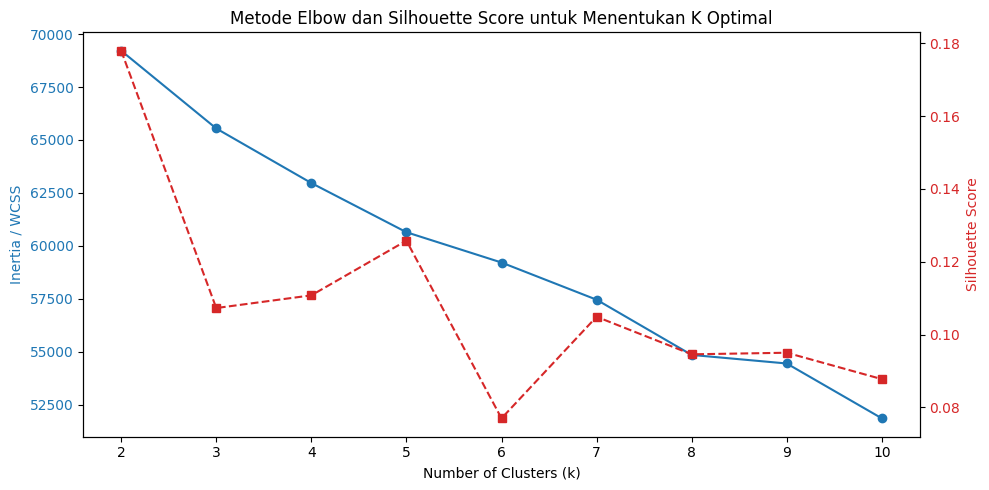

In [9]:
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, kmeans.labels_))

# Visualisasi Elbow & Silhouette
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Elbow
color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia / WCSS', color=color)
ax1.plot(K_range, inertia, marker='o', color=color, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

# Plot Silhouette
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(K_range, silhouette_scores, marker='s', color=color, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Metode Elbow dan Silhouette Score untuk Menentukan K Optimal')
fig.tight_layout()
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [10]:
# Tentukan K optimal (misalnya K=4 untuk hasil segmentasi yang lebih variatif)
k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters = kmeans.fit_predict(df_scaled)

# Masukkan hasil klaster ke dataframe asli dan dataframe terskala
df['Cluster'] = clusters
df_scaled['Cluster'] = clusters

# Tampilkan distribusi jumlah sampel di setiap cluster
print("=== Distribusi Jumlah Anggota per Cluster ===")
print(df['Cluster'].value_counts().sort_index())

# Tampilkan sampel data beserta klasternya
display(df[['ID', 'Cluster']].head())

=== Distribusi Jumlah Anggota per Cluster ===
Cluster
0     615
1     452
2     171
3    1002
Name: count, dtype: int64


,ID,Cluster
0,5524,1
1,2174,3
2,4141,1
3,6182,3
4,5324,0


# Step 9: Visualisasi klaster dengan PCA 2D

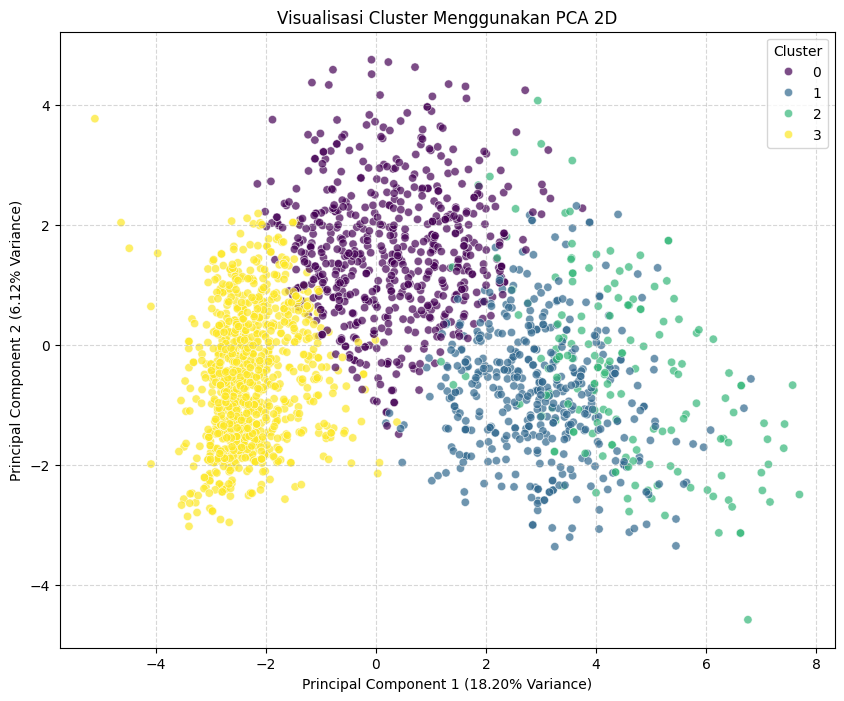

In [11]:
# Pastikan model K-Means dijalankan terlebih dahulu untuk mendapatkan label klaster jika belum ada
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
clusters = kmeans.fit_predict(df_scaled.drop(columns=['Cluster'], errors='ignore'))

# Masukkan kembali ke dataframe agar aman dari KeyError
df['Cluster'] = clusters
df_scaled['Cluster'] = clusters

# Inisialisasi PCA untuk mereduksi menjadi 2 komponen utama
pca = PCA(n_components=2, random_state=42)

# Lakukan fitting PCA pada data terskala (tanpa kolom 'Cluster')
features_for_pca = df_scaled.drop(columns=['Cluster'], errors='ignore')
try:
    # Menghapus kolom non-numerik jika ada yang tidak sengaja terbawa
    features_for_pca = features_for_pca.select_dtypes(include=[np.number])
except Exception:
    pass

pca_result = pca.fit_transform(features_for_pca)

# Buat DataFrame hasil PCA
df_pca = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])
df_pca['Cluster'] = df['Cluster']

# Visualisasi scatter plot 2D hasil PCA
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Cluster',
    palette='viridis',
    data=df_pca,
    legend='full',
    alpha=0.7
)

plt.title('Visualisasi Cluster Menggunakan PCA 2D')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}% Variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [12]:
# Tentukan fitur-fitur penting yang ingin kita analisis profilnya
fitur_profil = [
    'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth'
]

# Hitung rata-rata tiap fitur berdasarkan kelompok Cluster
cluster_profil = df.groupby('Cluster')[fitur_profil].mean().reset_index()

# Tambahkan informasi jumlah anggota di setiap klaster ke dalam tabel profil
cluster_size = df['Cluster'].value_counts().sort_index().reset_index()
cluster_size.columns = ['Cluster', 'Cluster_Size']

cluster_profil = pd.merge(cluster_size, cluster_profil, on='Cluster')

# Tampilkan profil klaster dalam bentuk tabel
print("=== Profil Rata-Rata Fitur per Cluster ===")
display(cluster_profil.T)

=== Profil Rata-Rata Fitur per Cluster ===


,0,1,2,3
Cluster,0.000000,1.000000,2.000000,3.000000
Cluster_Size,615.000000,452.000000,171.000000,1002.000000
Year_Birth,1964.143089,1967.957965,1969.356725,1971.956088
Income,57125.436585,74005.719027,81569.485380,34413.128244
Kidhome,0.237398,0.050885,0.052632,0.815369
Teenhome,0.933333,0.236726,0.128655,0.430140
Recency,48.554472,49.300885,49.830409,49.240519
MntWines,442.964228,489.205752,874.701754,37.622754
MntFruits,19.521951,71.690265,56.426901,4.848303
MntMeatProducts,125.549593,429.654867,469.128655,22.285429


# Simpulkan Analisa dari hasil

## Kesimpulan Akhir Analisis Segmentasi Pelanggan (Customer Personality Analysis)

Berdasarkan hasil algoritma K-Means dengan $K = 4$ dan reduksi dimensi menggunakan PCA, kita berhasil mengidentifikasi 4 segmen pelanggan utama yang sangat unik:

### 1. **Cluster 0: Loyal Bargain Hunters (615 Pelanggan)**
*   **Karakteristik:** Kelompok usia matang dengan pendapatan menengah (~$57,125).
*   **Perilaku:** Cukup konsisten dalam berbelanja, menyukai promo/diskon (`NumDealsPurchases` rata-rata 3.0), dan sering membeli langsung di toko fisik.
*   **Strategi Bisnis:** Berikan program loyalitas berkala dan penawaran bundling atau diskon khusus produk sehari-hari untuk menjaga retensi mereka.

### 2. **Cluster 1: Premium Spenders (452 Pelanggan)**
*   **Karakteristik:** Pelanggan mapan berpendapatan tinggi (~$74,005) dengan sedikit atau tanpa anak di rumah.
*   **Perilaku:** Pengeluaran tinggi untuk kategori produk mewah seperti Wine dan Daging. Jarang mencari diskon dan menyukai kenyamanan berbelanja lewat Katalog atau Toko Fisik.
*   **Strategi Bisnis:** Fokus pada pemasaran produk eksklusif/premium, tawarkan layanan VIP, dan kirimkan katalog fisik edisi terbatas karena mereka sangat merespons saluran penjualan ini.

### 3. **Cluster 2: Ultra High-Value Connoisseurs (171 Pelanggan)**
*   **Karakteristik:** Segmen elit dengan pendapatan tertinggi (~$81,569) dan tidak memiliki anak kecil.
*   **Perilaku:** Belanja paling rakus di semua kategori barang premium dengan volume pembelian tertinggi di toko, web, maupun katalog.
*   **Strategi Bisnis:** Target utama untuk kampanye produk paling premium/mewah (high-end). Berikan pelayanan personal (personalized concierge service) untuk memaksimalkan customer lifetime value.

### 4. **Cluster 3: Budget-Conscious Young Families (1.002 Pelanggan)**
*   **Karakteristik:** Kelompok terbesar, cenderung berusia lebih muda, pendapatan paling rendah (~$34,413), dan memiliki banyak anak kecil di rumah.
*   **Perilaku:** Pengeluaran belanja sangat rendah di seluruh kategori. Sering mengunjungi website setiap bulan (`NumWebVisitsMonth` rata-rata 6.5) tetapi jarang melakukan pembelian.
*   **Strategi Bisnis:** Tawarkan produk ramah keluarga (family pack) berharga ekonomis, promo pop-up murah di website untuk memicu pembelian impulsif, serta opsi pembayaran yang fleksibel.